In [2]:
%load_ext autoreload
%autoreload 2

from dask.distributed import Client
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap, BoundaryNorm, TwoSlopeNorm, CenteredNorm
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import utils, stats, plotting
from cdrmip_extremes.load_processed import load_processed
from cdrmip_extremes.configs import ssp_colour_dict, CDR_MODELS, PROC_DIR, FIG_DIR, SSP_MODELS as models

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [4]:
gsat = load_processed(PROC_DIR, 'ScenarioMIP', 'gsat')
gsat_rolling = load_processed(PROC_DIR, 'ScenarioMIP', 'gsat_rolling')
gwl_matching_years = load_processed(PROC_DIR, 'ScenarioMIP', 'gwl_matching_years')
sat_difference = load_processed(PROC_DIR, 'ScenarioMIP', 'gwl_differences')

In [5]:
sat_diff = {
    model: sat_difference[model]['ssp534-over'].gwl_differences for model in sat_difference.keys() 
    if model not in ['multi_model_median']
}

sat_diff_agreement = stats.calc_agreement(sat_diff)
sat_diff['Multi-Model Median'] = sat_difference['multi_model_median']['ssp534-over']

In [6]:
sat_diff_union = {
    model: {
        'ssp534-over': sat_difference[model]['ssp534-over'] 
    } for model in sat_difference.keys() if model in CDR_MODELS
}

# sat_diff_agreement_union = stats.calc_agreement(sat_diff_union)
sat_diff_union['Multi-Model Median'] = {
    'ssp534-over': xr.concat(
        [sat_diff_union[model]['ssp534-over'] for model in sat_diff_union.keys()],
        dim='model',
        compat='override',
        coords='minimal'
    ).median(dim='model')
}

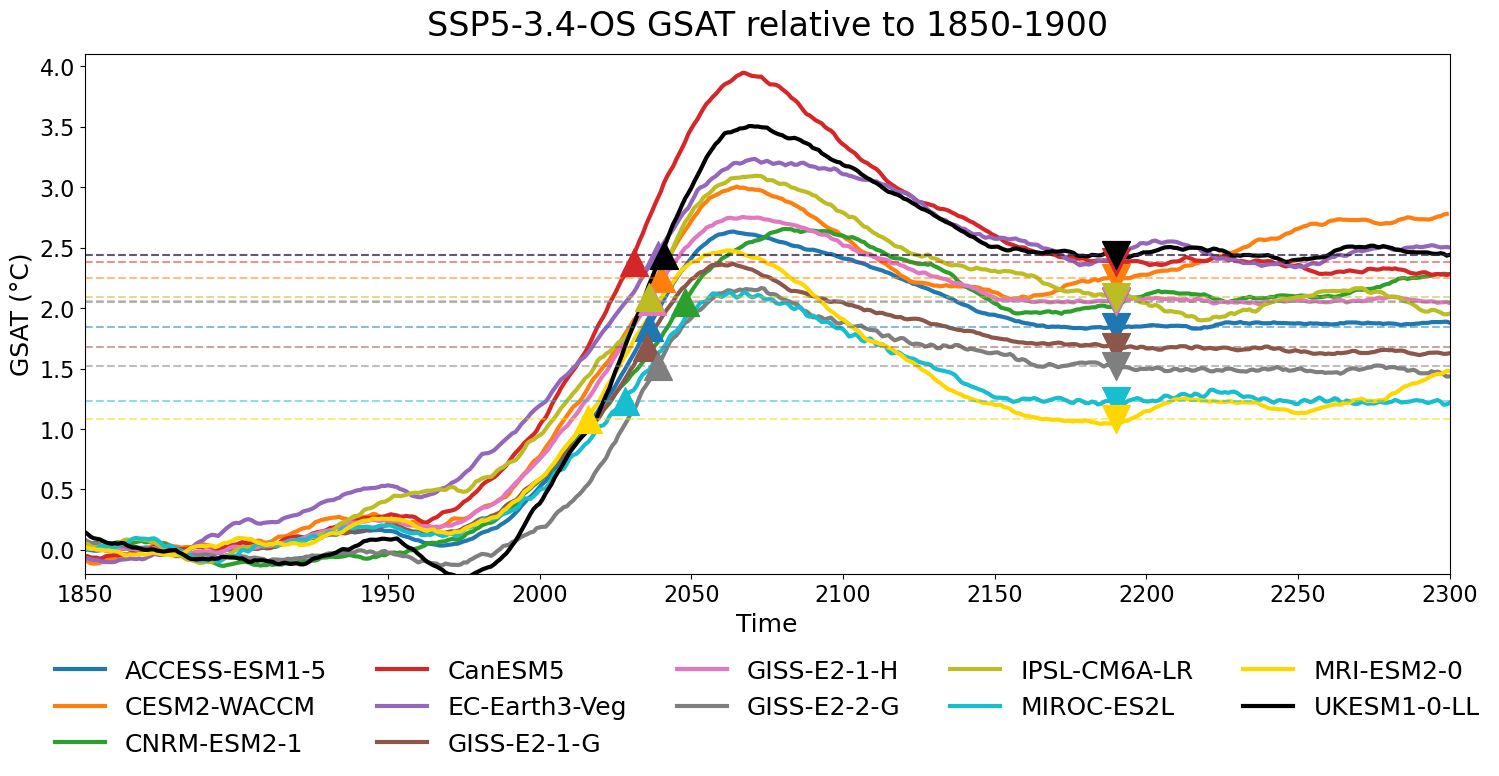

In [7]:
fig = plotting.plot_gsat_timeseries(
    gsat_rolling,
    gwl_matching_years,
    ssp_colour_dict,
    title="SSP5-3.4-OS GSAT relative to 1850-1900",
    fig_dir=FIG_DIR,folder='supplementary',file_name="figure_S2.jpg"
)

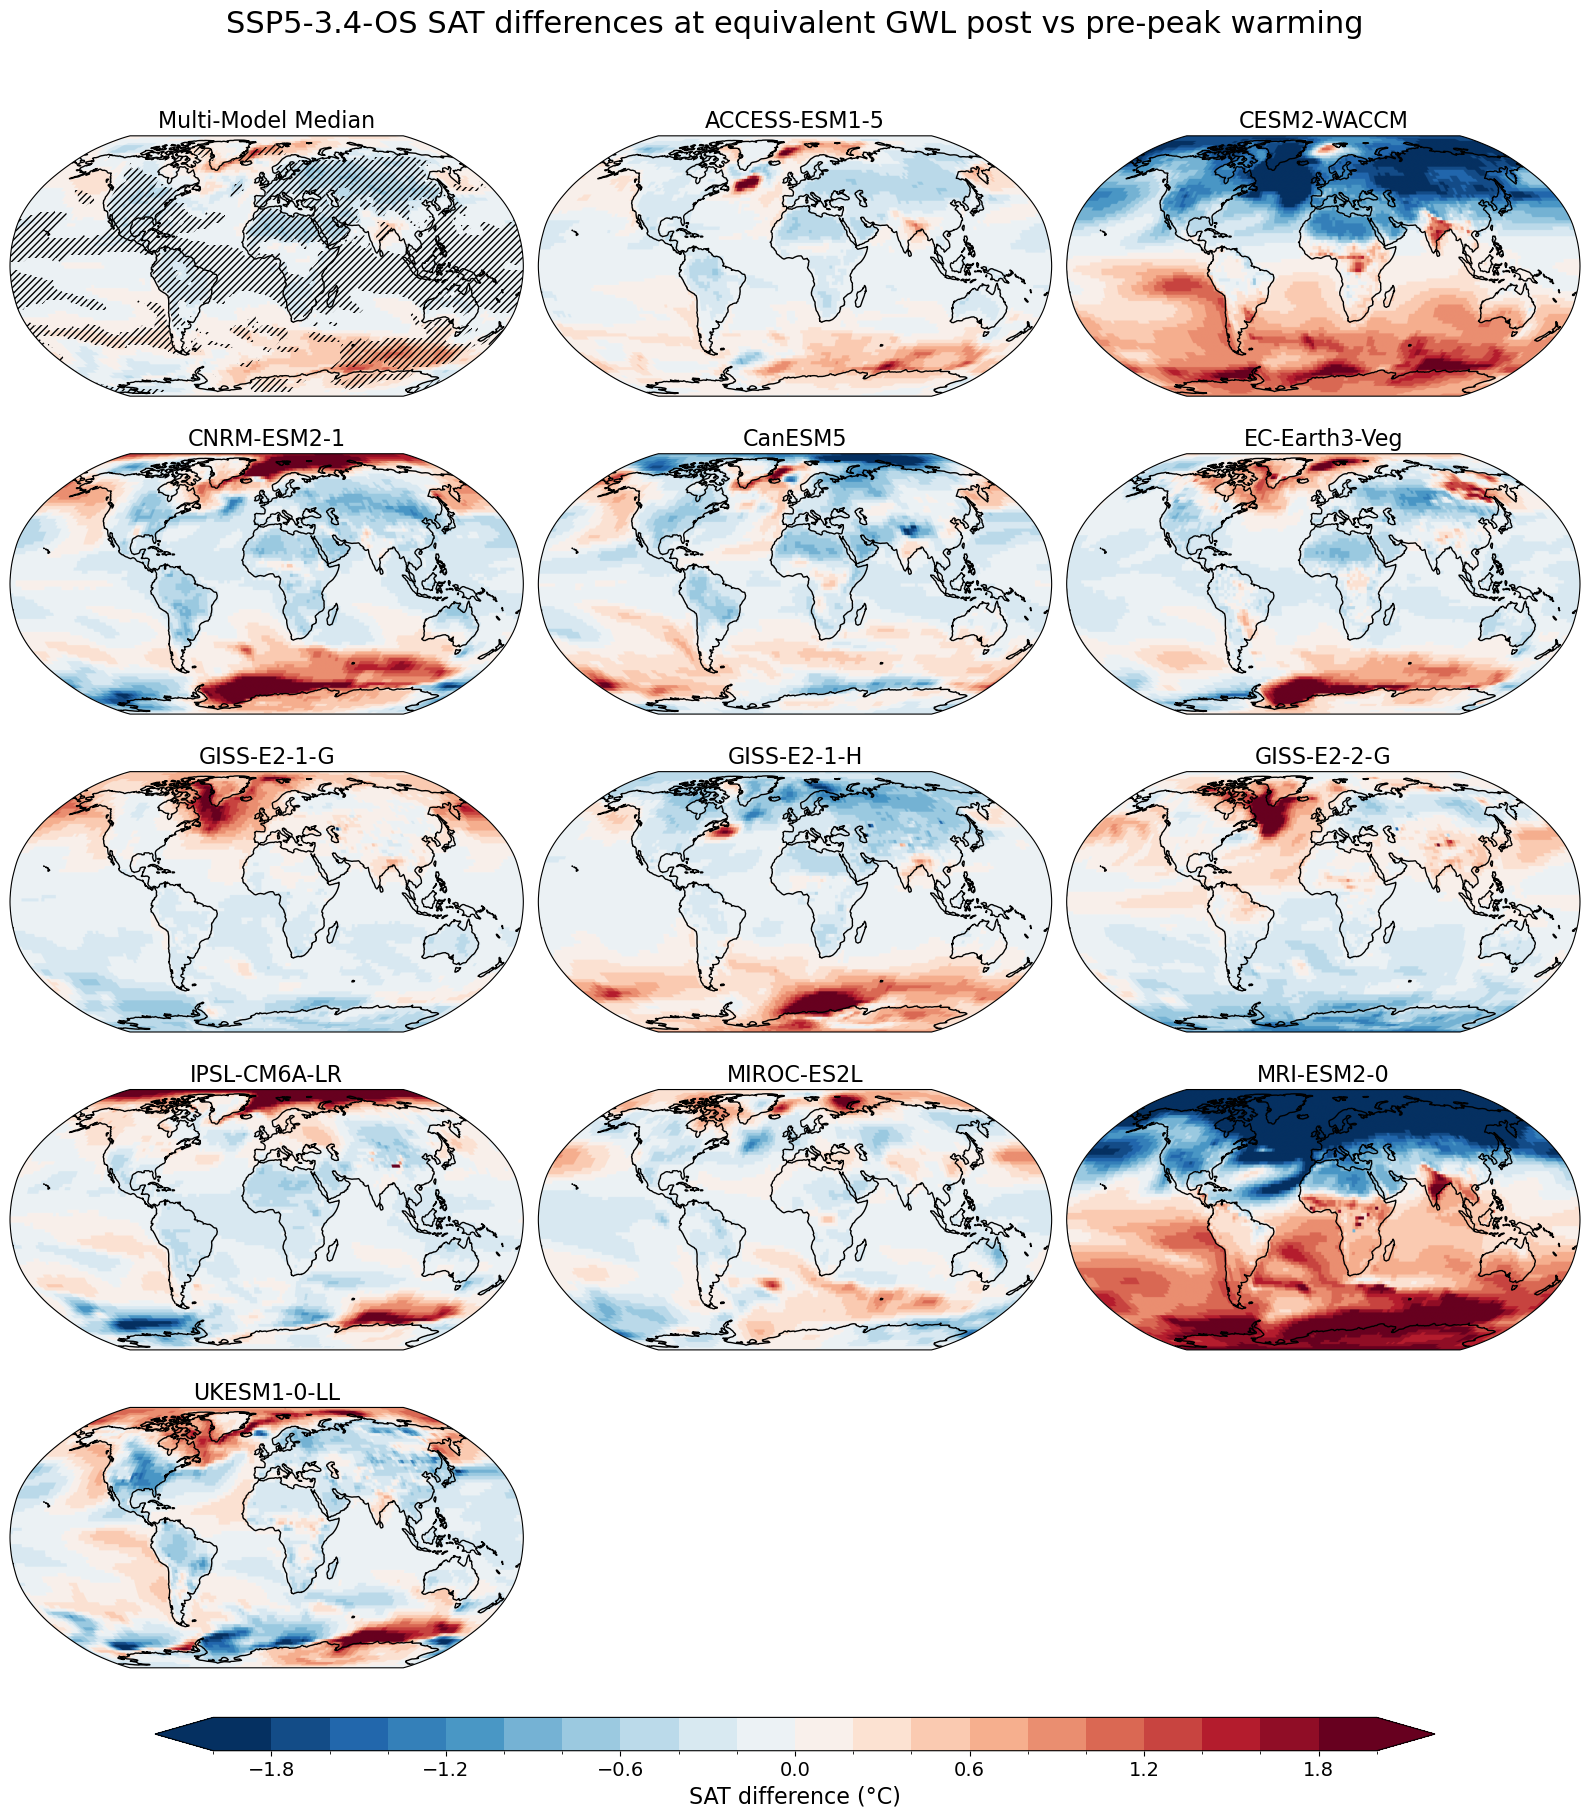

In [21]:
fig = plotting.plot_gwl_diff(
    sat_difference,
    expt='ssp534-over',
    levels=np.linspace(-2,2,21),
    agreement = sat_diff_agreement,
    suptitle = "SSP5-3.4-OS SAT differences at equivalent GWL post vs pre-peak warming"
)

fig.savefig(
    FIG_DIR / "supplementary" / "figure_S3.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)